# Histogram of Oriented Gradients (HOG)

A **HOG descriptor** describes the shape of an object by the directions of its edges. The image is divided into small cells. In each cell, the gradients are counted in a histogram of their orientations, weighted by how strong they are. Neighbouring cells are grouped into blocks, and each block is normalised. The result is one long vector of numbers that describes the shape, and it is robust to small changes in lighting and position.

HOG was introduced by Dalal and Triggs (2005) for pedestrian detection, where it was used with a linear SVM. It is a classical feature, and it is still a useful example of how shape is turned into numbers.

This notebook does the following on a photo of a truck:
1. Computes the image gradients, their strength and their direction.
2. Builds the orientation histogram of one cell by hand.
3. Computes the HOG descriptor with scikit-image, with single-cell blocks and with the standard settings.
4. Shows why block normalisation matters, by darkening the image.
5. Saves all results to `output/`.

## 1. Imports

- `cv2` (OpenCV): image I/O, Sobel gradients and polar conversion
- `matplotlib`: displaying images and histograms
- `numpy`: array operations
- `skimage` (scikit-image): the `hog` function and intensity rescaling
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import exposure
from skimage.feature import hog

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. Configuration

- `INPUT_PATH`: the truck photo.
- `GRADIENT_KSIZE`: the size of the Sobel kernel, 3 or 7. Common choices are 3 and 7.
- `CELL`: the size of a cell in pixels, `(rows, columns)`. 16 × 16 is a common choice.
- `ORIENTATIONS`: the number of bins in each orientation histogram. 9 is the number used in the original method.
- `DEMO_CELL`: the top-left corner `(row, column)` of the cell whose histogram is computed by hand in section 4.
- All results are saved to `OUTPUT_DIR`.

In [2]:
INPUT_PATH = Path("truck_free_s.jpg")
OUTPUT_DIR = Path("output")

GRADIENT_KSIZE = 3
CELL = (16, 16)
ORIENTATIONS = 9
DEMO_CELL = (256, 480)  # (row, column) of the top-left corner of the cell in section 4

## 3. Load the image and helper functions

Helper functions:
- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error.
- `show_images` shows several images side by side. Colour images are converted from BGR to RGB before display.
- `to_uint8` makes a signed or float image displayable, by scaling it to 0-255.
- `save_image` writes an image and checks the result.

In [3]:
def load_image(path: Path) -> np.ndarray:
    """Load a colour image with OpenCV (BGR order) and raise a clear error if it fails."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray")
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def to_uint8(values: np.ndarray) -> np.ndarray:
    """Scale a float image to 0-255 so that it can be displayed and saved."""
    return cv2.normalize(values, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

Image size (height, width): (678, 957)


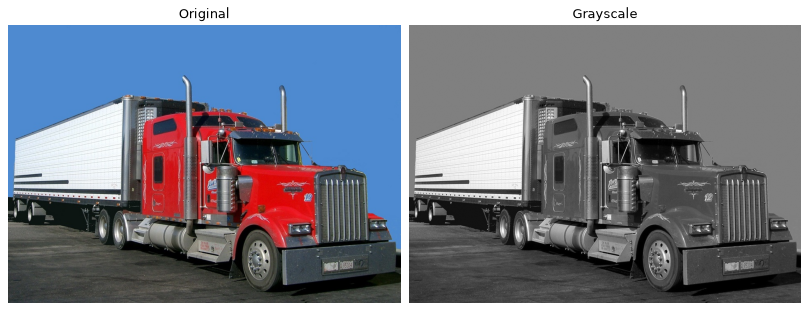

In [4]:
image = load_image(INPUT_PATH)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
print(f"Image size (height, width): {gray.shape}")
show_images({"Original": image, "Grayscale": gray}, cols=2)

## 4. Gradients: strength and direction

A gradient is the change of brightness. The Sobel filter gives it in the horizontal direction and the vertical direction:
- `dx=1, dy=0` gives $G_x$, the change from left to right. It responds to vertical edges.
- `dx=0, dy=1` gives $G_y$, the change from top to bottom. It responds to horizontal edges.

The strength of the gradient is $|G| = \sqrt{G_x^2 + G_y^2}$, and its direction is $\theta = \arctan(G_y / G_x)$. HOG uses the direction without its sign, so each edge votes for the same bin whether it goes from light to dark or from dark to light, and the angles are taken modulo 180°.

Note that the Sobel calls are easy to name the wrong way round: `dx=0, dy=1` measures the vertical change, so it belongs to the y direction. The names below match what the kernels measure.

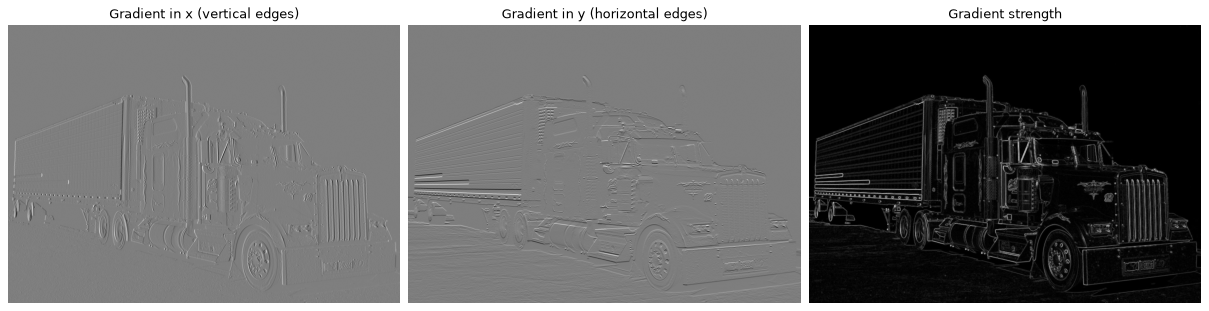

In [5]:
gx = cv2.Sobel(gray, cv2.CV_64F, dx=1, dy=0, ksize=GRADIENT_KSIZE)
gy = cv2.Sobel(gray, cv2.CV_64F, dx=0, dy=1, ksize=GRADIENT_KSIZE)
magnitude, angle = cv2.cartToPolar(gx, gy, angleInDegrees=True)  # angle in 0-360 degrees
unsigned_angle = np.mod(angle, 180.0)  # HOG uses the unsigned direction, 0-180 degrees

show_images({
    "Gradient in x (vertical edges)": to_uint8(gx),
    "Gradient in y (horizontal edges)": to_uint8(gy),
    "Gradient strength": to_uint8(magnitude),
}, cols=3)

## 5. The orientation histogram of one cell

A cell is a small square, here `CELL` pixels wide. Each pixel in the cell votes for the orientation bin that contains its direction, with a vote equal to its gradient strength. The histogram of the cell is the sum of these votes.

The cell below is computed by hand, so that the bins are visible. The bars show the total strength of the edges at each direction. The bin width is 180° divided by the number of orientations.

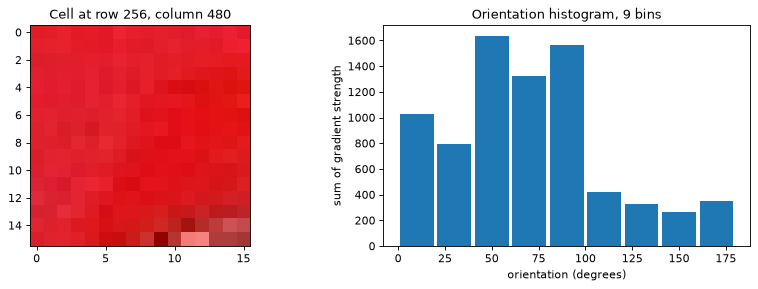

In [6]:
r0, c0 = DEMO_CELL
rows = slice(r0, r0 + CELL[0])
cols = slice(c0, c0 + CELL[1])

bin_width = 180.0 / ORIENTATIONS
bins = np.floor(unsigned_angle[rows, cols] / bin_width).astype(int) % ORIENTATIONS
histogram = np.bincount(bins.ravel(), weights=magnitude[rows, cols].ravel(), minlength=ORIENTATIONS)

centres = np.arange(ORIENTATIONS) * bin_width + bin_width / 2
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].imshow(cv2.cvtColor(image[rows, cols], cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Cell at row {r0}, column {c0}")
axes[1].bar(centres, histogram, width=bin_width * 0.9)
axes[1].set_xlabel("orientation (degrees)")
axes[1].set_ylabel("sum of gradient strength")
axes[1].set_title(f"Orientation histogram, {ORIENTATIONS} bins")
plt.show()

## 6. The HOG descriptor

`skimage.feature.hog` computes the cell histograms for the whole image and normalises them over **blocks** of neighbouring cells. Two settings are compared:
- **Single-cell blocks:** one cell per block, with the default normalisation.
- **The standard setting:** blocks of 2 × 2 cells, with L2-Hys normalisation, which clips large values and normalises again. It also compresses the intensities with a square root, which reduces the effect of very strong edges.

`features` is the descriptor. Its shape shows the grid of blocks, the cells in each block and the number of orientations. `hog_image` is a picture of the orientations in every cell.

Single-cell blocks: block grid and descriptor shape (42, 59, 1, 1, 9)
Standard settings: block grid and descriptor shape (41, 58, 2, 2, 9)
Length of the standard descriptor vector: 85608


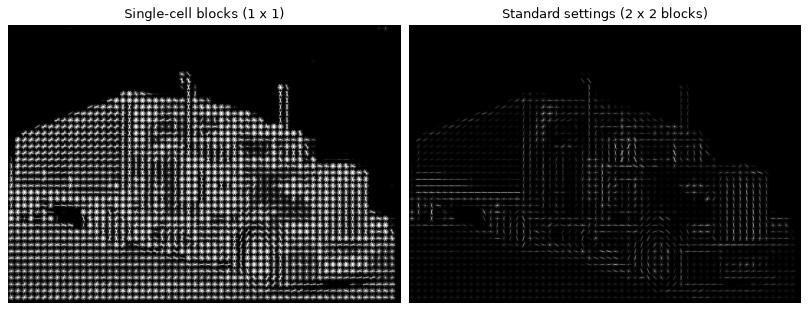

In [7]:
single_features, single_image = hog(
    gray, orientations=ORIENTATIONS, pixels_per_cell=CELL, cells_per_block=(1, 1),
    transform_sqrt=False, visualize=True, feature_vector=False)

standard_features, standard_image = hog(
    gray, orientations=ORIENTATIONS, pixels_per_cell=CELL, cells_per_block=(2, 2),
    block_norm="L2-Hys", transform_sqrt=True, visualize=True, feature_vector=False)

print(f"Single-cell blocks: block grid and descriptor shape {single_features.shape}")
print(f"Standard settings: block grid and descriptor shape {standard_features.shape}")
print(f"Length of the standard descriptor vector: {standard_features.size}")

show_images({
    "Single-cell blocks (1 x 1)": exposure.rescale_intensity(single_image, in_range=(0, 2)),
    "Standard settings (2 x 2 blocks)": exposure.rescale_intensity(standard_image, in_range=(0, 2)),
}, cols=2)

## 7. Why normalisation matters

The descriptor should not change much when the light changes. The photo is darkened to half its brightness, and the HOG descriptor is computed again for two block sizes, with L2-Hys normalisation.

The photo is used as float values here. Rounding a dark 8-bit image to half its brightness adds visible quantisation noise, and the square-root compression amplifies it, so the change in the descriptor is much larger. The last line of the cell shows that case.

In [8]:
gray_float = gray.astype(np.float64) / 255.0
dark_float = gray_float * 0.5
dark = (gray.astype(np.float32) * 0.5).astype(np.uint8)

for name, options in {
    "L2-Hys, 1 x 1 blocks": dict(cells_per_block=(1, 1)),
    "L2-Hys, 2 x 2 blocks": dict(cells_per_block=(2, 2)),
}.items():
    bright_desc = hog(gray_float, orientations=ORIENTATIONS, pixels_per_cell=CELL, block_norm="L2-Hys",
                      transform_sqrt=False, feature_vector=True, **options)
    dark_desc = hog(dark_float, orientations=ORIENTATIONS, pixels_per_cell=CELL, block_norm="L2-Hys",
                    transform_sqrt=False, feature_vector=True, **options)
    change = np.linalg.norm(dark_desc - bright_desc) / np.linalg.norm(bright_desc)
    print(f"{name}: relative change when darkened by half (float): {change:.2%}")

bright_8bit = hog(gray, orientations=ORIENTATIONS, pixels_per_cell=CELL, cells_per_block=(2, 2),
                  block_norm="L2-Hys", transform_sqrt=True, feature_vector=True)
dark_8bit = hog(dark, orientations=ORIENTATIONS, pixels_per_cell=CELL, cells_per_block=(2, 2),
                block_norm="L2-Hys", transform_sqrt=True, feature_vector=True)
change_8bit = np.linalg.norm(dark_8bit - bright_8bit) / np.linalg.norm(bright_8bit)
print(f"Standard settings on 8-bit images, darkened by half: {change_8bit:.2%}")

L2-Hys, 1 x 1 blocks: relative change when darkened by half (float): 0.03%
L2-Hys, 2 x 2 blocks: relative change when darkened by half (float): 0.01%


Standard settings on 8-bit images, darkened by half: 10.91%


## 8. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix.

In [9]:
stem = INPUT_PATH.stem
outputs = {
    "gradient_strength": to_uint8(magnitude),
    "hog_single_cell_blocks": exposure.rescale_intensity(single_image, in_range=(0, 2)),
    "hog_standard_settings": exposure.rescale_intensity(standard_image, in_range=(0, 2)),
}
for suffix, result in outputs.items():
    save_image(OUTPUT_DIR / f"{stem}_{suffix}.jpg", to_uint8(result) if result.dtype != np.uint8 else result)

Saved output/truck_free_s_gradient_strength.jpg
Saved output/truck_free_s_hog_single_cell_blocks.jpg
Saved output/truck_free_s_hog_standard_settings.jpg


## 9. Conclusion

- A **gradient** gives the strength and the direction of an edge. HOG uses the unsigned direction, so the bins range from 0° to 180°.
- Each **cell** collects a histogram of its gradient directions, weighted by strength. The histograms describe the local shape.
- **Block normalisation** makes the descriptor robust to changes in brightness and contrast. Darkening the photo changes the descriptor by well under 1% when the input is a float image. On 8-bit images, rounding in dark areas makes the change larger, so the image should be handled in float where precision matters.
- The **block size** sets how much context each normalised block sees. The 2 × 2 setting gives a longer descriptor that is the standard for detection.
- HOG describes a shape at one size and in one window. An object detector slides the window over the image at several scales, using an image pyramid, and classifies each window with an SVM.

**Limits of this method**
- HOG is sensitive to changes in pose and viewpoint, and it needs a large window for each object.
- The features are fixed by hand, so the descriptor cannot learn which parts of a shape matter.

**Current standards beyond this notebook**
- **Learned features:** convolutional neural networks learn the edge and shape detectors from labelled images. Modern detectors such as YOLO and Faster R-CNN, mentioned in the template matching notebook, replace HOG with features learned in this way.
- HOG with an SVM is still used where a small, fast and explainable detector is enough. I have not benchmarked it against current detectors here.